# Análise Exploratória de Dados (AED) com Python

## Exemplo prático: encontrando inconsistências em registros de livros

Primeiro vamos explorar, levantar hipóteses, identificar problemas e só depois decidir o que precisa ser tratato.

- Estruturas e tipos de dados;
- Valores ausentes;
- Registros duplicados;
- Catetegorias inconsistentes;
- Estatística descritiva;
- Distribuição de variáveis;
- Valores suspeitos e outliers;
- Relações entre variáveis;
- Padrão por categoria;

# 1. Importando as bilbiotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Carregando os dados

In [2]:
livros = pd.read_csv('livros.csv', sep=',', encoding='utf-8')

# 3. Olhando os primeiros registros do DataFrame (amostra de dados)

In [3]:
livros.head()

,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
0,1,Extraordinário,R. J. Palacio,Drama,"2012,0",320,"4,8",9800,"49,9",Português
1,2,Como Eu Era Antes de Você,Jojo Moyes,Romance,"2012,0",320,"4,7",11200,"49,9",Português
2,3,É Assim que Acaba,Colleen Hoover,Romance,"2018,0",368,"4,7",12500,"49,9",Português
3,4,É Assim que Começa,Colleen Hoover,Romance,"2022,0",336,"4,8",11200,"54,9",Português
4,5,Verity,Colleen Hoover,Suspense,"2018,0",320,"4,7",9800,"49,9",Português


# 4. Qual é o tamanho do conjunto de dados que estamos analisando?

In [4]:
livros.shape

(50, 10)

# 5. Conhecendo as colunas e os tipos

In [5]:
livros.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_livro        50 non-null     int64 
 1   titulo          50 non-null     object
 2   autor           50 non-null     object
 3   categoria       50 non-null     object
 4   ano_publicacao  48 non-null     object
 5   paginas         50 non-null     int64 
 6   avaliacao       49 non-null     object
 7   qtd_avaliacoes  50 non-null     int64 
 8   preco           49 non-null     object
 9   idioma          50 non-null     object
dtypes: int64(3), object(7)
memory usage: 4.0+ KB


### Podemos olhar colunas categoricas, por exemplo, para contar a quantidade de registros que refenciam determinada coluna (categoria)

In [6]:
livros.value_counts('categoria')

categoria
Drama                10
Romance               8
Fantasia              5
Autoajuda             5
Suspense              5
História              4
Ficção Científica     4
Financeiro            4
Ficção                2
AUTOAJUDA             1
Tecnologia            1
suspense              1
Name: count, dtype: int64

# 6. Visualizar uma amostra maior

In [7]:
livros.head(10)

,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
0,1,Extraordinário,R. J. Palacio,Drama,"2012,0",320,"4,8",9800,"49,9",Português
1,2,Como Eu Era Antes de Você,Jojo Moyes,Romance,"2012,0",320,"4,7",11200,"49,9",Português
2,3,É Assim que Acaba,Colleen Hoover,Romance,"2018,0",368,"4,7",12500,"49,9",Português
3,4,É Assim que Começa,Colleen Hoover,Romance,"2022,0",336,"4,8",11200,"54,9",Português
4,5,Verity,Colleen Hoover,Suspense,"2018,0",320,"4,7",9800,"49,9",Português
5,6,A Paciente Silenciosa,Alex Michaelides,Suspense,"2019,0",364,"4,7",9200,"52,9",Português
6,7,A Empregada,Freida McFadden,Suspense,"2022,0",336,"4,6",11400,"49,9",Português
7,8,A Empregada Está de Olho,Freida McFadden,suspense,"2023,0",336,"4,5",8300,"54,9",Português
8,9,A Biblioteca da Meia-Noite,Matt Haig,Ficção,"2020,0",308,"4,7",8700,"54,9",Português
9,10,O Homem de Giz,C. J. Tudor,Suspense,"2018,0",272,"4,5",5400,"44,9",Português


In [8]:
livros.tail(10)

,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
40,41,Pequenos Incêndios por Toda Parte,Celeste Ng,Drama,"2017,0",400,"4,6",4300,"54,9",Português
41,42,A Vida Mentirosa dos Adultos,Elena Ferrante,Drama,"2019,0",336,"4,2",3400,549,Português
42,43,O Avesso da Pele,Jeferson Tenório,Drama,"2020,0",192,"4,7",3800,"39,9",Português
43,44,Tudo é Rio,Carla Madeira,Romance,"2014,0",210,"4,8",10500,"39,9",Português
44,45,A Hipótese do Amor,Ali Hazelwood,Romance,NaN,368,4.7,10800,59.9,Português
45,46,Pessoas Normais,Sally Rooney,Romance,"2018,0",264,4.4,7600,42.9,Português
46,47,A Morte é um Dia que Vale a Pena Viver,Ana Claudia Quintana Arantes,Autoajuda,"2016,0",192,4.7,5200,44.9,Português
47,48,O Poder da Autorresponsabilidade,Paulo Vieira,Autoajuda,"2017,0",160,4.6,6800,42.9,Português
48,49,Em Agosto nos Vemos,Gabriel García Márquez,Drama,"2024,0",144,4.3,3900,39.9,Português
49,50,Amor & Gelato,Jenna Evans Welch,Romance,2016,384,4.5,4200,49.9,Português


# 7. Valores ausentes

In [9]:
livros.isna().sum()

id_livro          0
titulo            0
autor             0
categoria         0
ano_publicacao    2
paginas           0
avaliacao         1
qtd_avaliacoes    0
preco             1
idioma            0
dtype: int64

# 8. Registros duplicados

In [10]:
livros.duplicated().sum()

np.int64(0)

# 9. Visualizar a distribuição de dados numericos

Explorar conjuntos de dados visualmente (histograma)

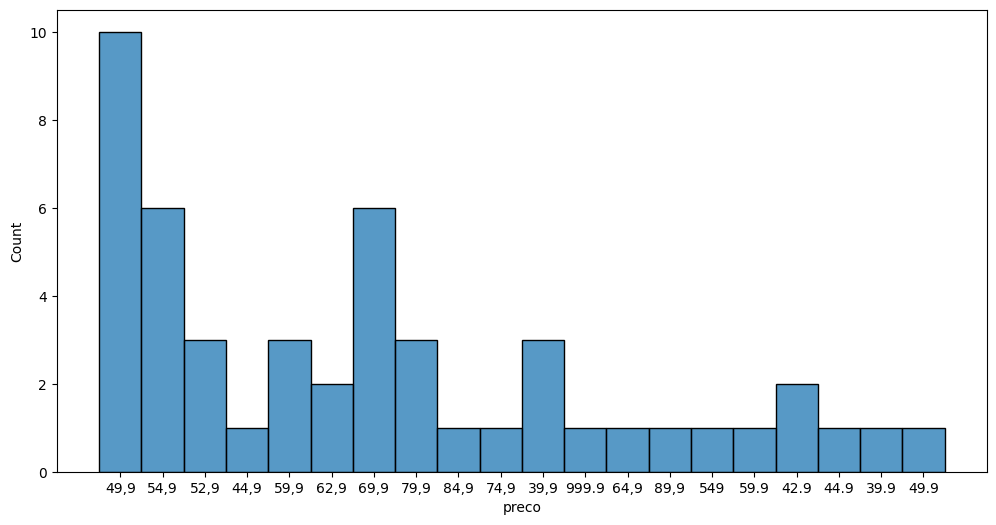

In [11]:
plt.figure(figsize=(12, 6))
sns.histplot(data=livros, x='preco')
plt.show()

### Boxplot do preço

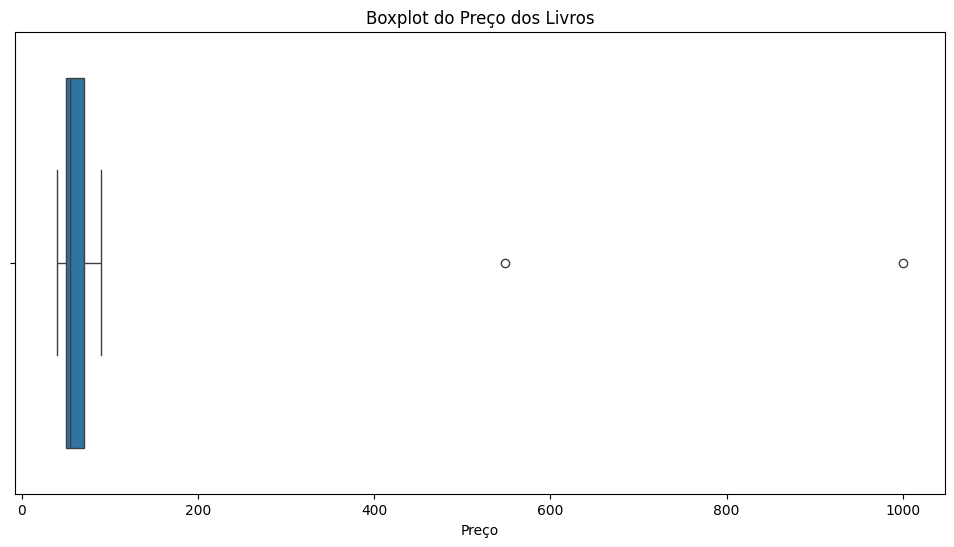

In [12]:
livros["preco_num"] = pd.to_numeric(
    livros["preco"].astype("string").str.replace(",", ".")
)

plt.figure(figsize=(12, 6))
sns.boxplot(x=livros["preco_num"])
plt.title("Boxplot do Preço dos Livros")
plt.xlabel("Preço")
plt.show()
